In [ ]:
import xarray as xr
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import PowerTransformer
import numpy as np

In [ ]:
ds_true = xr.open_dataset("/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr")
ds_true = ds_true.isel(time=slice(334*24, 364*24))
ds_true["prev_sigWaveHeight"] = ds_true["sigWaveHeight"].shift({"time": 1})
ds_true["delta_sigWaveHeight"] = ds_true["sigWaveHeight"].diff("time")
# need to remove the first entry
ds_true = ds_true.isel(time=slice(1, None))

In [ ]:
ds_true

<xarray.Dataset> Size: 51GB
Dimensions:                  (time: 719, nSCHISM_hgrid_node: 589428,
                              nSCHISM_hgrid_edge: 1758191, two: 2,
                              nSCHISM_hgrid_face: 1168634,
                              nMaxSCHISM_hgrid_face_nodes: 4)
Coordinates:
  * time                     (time) datetime64[ns] 6kB 2020-11-30T02:00:00 .....
    SCHISM_hgrid_edge_x      (nSCHISM_hgrid_edge) float32 7MB ...
    SCHISM_hgrid_edge_y      (nSCHISM_hgrid_edge) float32 7MB ...
    SCHISM_hgrid_face_x      (nSCHISM_hgrid_face) float32 5MB ...
    SCHISM_hgrid_face_y      (nSCHISM_hgrid_face) float32 5MB ...
    SCHISM_hgrid_node_x      (nSCHISM_hgrid_node) float32 2MB ...
    SCHISM_hgrid_node_y      (nSCHISM_hgrid_node) float32 2MB ...
Dimensions without coordinates: nSCHISM_hgrid_node, nSCHISM_hgrid_edge, two,
                                nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes
Data variables: (12/18)
    depthAverageVelX         (time, nSCHISM_hgrid_node) float32 2GB ...
    depthAverageVelY         (time, nSCHISM_hgrid_node) float32 2GB ...
    dryFlagNode              (time, nSCHISM_hgrid_node) float32 2GB ...
    elevation                (time, nSCHISM_hgrid_node) float32 2GB ...
    meanDirSpreading         (time, nSCHISM_hgrid_node) float32 2GB ...
    meanWaveDirection        (time, nSCHISM_hgrid_node) float32 2GB ...
    ...                       ...
    sigWaveHeight            (time, nSCHISM_hgrid_node) float32 2GB ...
    TM10                     (time, nSCHISM_hgrid_node) float32 2GB ...
    windSpeedX               (time, nSCHISM_hgrid_node) float32 2GB ...
    windSpeedY               (time, nSCHISM_hgrid_node) float32 2GB ...
    prev_sigWaveHeight       (time, nSCHISM_hgrid_node) float32 2GB 4.675e-07...
    delta_sigWaveHeight      (time, nSCHISM_hgrid_node) float32 2GB 3.626e-07...

In [ ]:
ds_true[list(ds_true.data_vars)]

<xarray.Dataset> Size: 51GB
Dimensions:                  (time: 719, nSCHISM_hgrid_node: 589428,
                              nSCHISM_hgrid_edge: 1758191, two: 2,
                              nSCHISM_hgrid_face: 1168634,
                              nMaxSCHISM_hgrid_face_nodes: 4)
Coordinates:
  * time                     (time) datetime64[ns] 6kB 2020-11-30T02:00:00 .....
    SCHISM_hgrid_edge_x      (nSCHISM_hgrid_edge) float32 7MB ...
    SCHISM_hgrid_edge_y      (nSCHISM_hgrid_edge) float32 7MB ...
    SCHISM_hgrid_face_x      (nSCHISM_hgrid_face) float32 5MB ...
    SCHISM_hgrid_face_y      (nSCHISM_hgrid_face) float32 5MB ...
    SCHISM_hgrid_node_x      (nSCHISM_hgrid_node) float32 2MB ...
    SCHISM_hgrid_node_y      (nSCHISM_hgrid_node) float32 2MB ...
Dimensions without coordinates: nSCHISM_hgrid_node, nSCHISM_hgrid_edge, two,
                                nSCHISM_hgrid_face, nMaxSCHISM_hgrid_face_nodes
Data variables: (12/18)
    depthAverageVelX         (time, nSCHISM_hgrid_node) float32 2GB ...
    depthAverageVelY         (time, nSCHISM_hgrid_node) float32 2GB ...
    dryFlagNode              (time, nSCHISM_hgrid_node) float32 2GB ...
    elevation                (time, nSCHISM_hgrid_node) float32 2GB ...
    meanDirSpreading         (time, nSCHISM_hgrid_node) float32 2GB ...
    meanWaveDirection        (time, nSCHISM_hgrid_node) float32 2GB ...
    ...                       ...
    sigWaveHeight            (time, nSCHISM_hgrid_node) float32 2GB ...
    TM10                     (time, nSCHISM_hgrid_node) float32 2GB ...
    windSpeedX               (time, nSCHISM_hgrid_node) float32 2GB ...
    windSpeedY               (time, nSCHISM_hgrid_node) float32 2GB ...
    prev_sigWaveHeight       (time, nSCHISM_hgrid_node) float32 2GB 4.675e-07...
    delta_sigWaveHeight      (time, nSCHISM_hgrid_node) float32 2GB 3.626e-07...

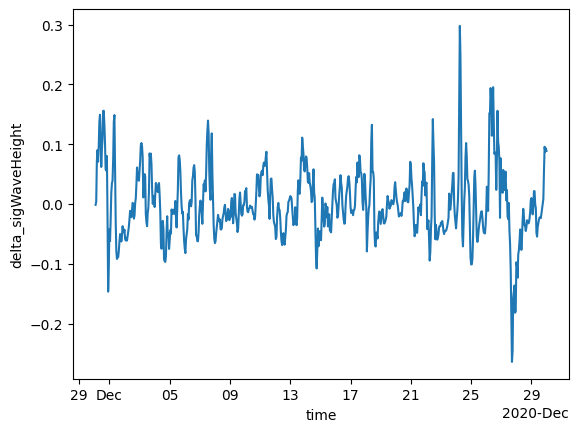

In [ ]:
ds_true["delta_sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").plot()

In [ ]:
tmax = ds_true["delta_sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").argmax().compute().item()
tmax # index of highest average wave height change

580

In [ ]:
tmin = ds_true["delta_sigWaveHeight"].isel(time=slice(10, -10)).std(dim="nSCHISM_hgrid_node").argmin().compute().item()
tmin # index of least variability in wave height change

142

In [ ]:
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/train_ml/xgboost_1h/runs/2026-02-13_09-56-58/predictions.nc") # best sweep 90
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/train_ml/xgboost_1h/runs/2026-02-13_10-31-26/predictions.nc") # best sweep 120

#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict/runs/2026-02-13_11-44-38/predictions.nc") # densenet
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/train_ml/xgboost_default/runs/2026-02-13_12-19-11/predictions.nc") # xgboost 3 params 120
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/train_ml/xgboost_1h/runs/2026-02-13_10-33-27/predictions.nc") # xgboost swh
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/train_ml/xgboost_1h/runs/2026-02-13_12-49-31/predictions.nc") # xgboost 120
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict/runs/2026-02-13_13-08-42/predictions.nc") # densenet swh
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict/runs/2026-02-15_20-57-16/predictions.nc") # densenet swh best from sweep
#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict/runs/2026-02-16_08-51-23/predictions.nc") # densenet dswh best from sweep

#ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/train_ml/xgboost_1h/runs/2026-02-20_04-19-34/predictions.nc")
ds_pred = xr.open_dataset("/work/ka1176/caroline/gitlab/wave-wind-model-emulator/logs/predict_lstm/runs/2026-03-26_08-13-03/predictions.nc") # lstm 3

In [ ]:
ds_true = ds_true.isel(time=slice(-len(ds_pred.time), None)) # account for sequence length

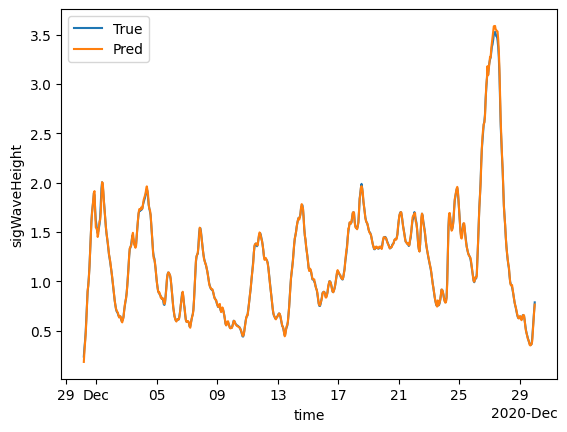

In [ ]:
ds_true["sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").plot(label="True")
ds_pred["sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").plot(label="Pred")
plt.legend()

In [ ]:
import pyvista as pv
import numpy as np



x = ds_true.SCHISM_hgrid_node_x.values
y = ds_true.SCHISM_hgrid_node_y.values

# Create 3D points (PyVista requires 3D coordinates)
points = np.column_stack([x, y, np.zeros_like(x)])
face_node_connectivity = xr.open_dataset("/work/bg1186/g260200/RUN04b_JUWELS_wpile/outputs_all/out2d_1.nc").isel(time=0).SCHISM_hgrid_face_nodes.values

In [ ]:
def fc_to_pyv(ix):
    # Convert face connectivity to PyVista format
    #face_node_connectivity = ds_true.isel(time=ix).SCHISM_hgrid_face_nodes.values

    # Handle both triangular (NaN in 4th column) and quad faces
    faces = []
    for face_nodes in face_node_connectivity:
        if np.isnan(face_nodes[3]):
            # Triangular face
            faces.append(3)  # number of points
            faces.extend(face_nodes[:3].astype(int))
        else:
            # Quadrilateral face
            faces.append(4)  # number of points
            faces.extend(face_nodes.astype(int))

    faces = np.array(faces, dtype=int)
    return faces

def plot_feature_map(ix, features):
    faces = fc_to_pyv(ix)

    # meshes
    meshes = [pv.PolyData(points, faces) for _ in range(len(features))]
    for feature, mesh in zip(features, meshes):
        mesh["z"] = ds_true.isel(time=ix)[feature].values

    plotter = pv.Plotter(border=True, shape=(1, len(features)), window_size=(400*len(features), 400))

    for i, feat, mesh in zip(range(len(meshes)), features, meshes):
        plotter.subplot(0, i)
        plotter.add_text(feat, font_size=14)
        plotter.add_mesh(mesh, scalars="z", cmap="viridis", show_edges=False, scalar_bar_args={"title": feat})
        plotter.view_xy()
        plotter.enable_parallel_projection()

    plotter.show()

def plot_target_bias_map(ix, target):
    
    faces = fc_to_pyv(ix)
    # Create the mesh
    mesh_true = pv.PolyData(points, faces)
    mesh_pred = pv.PolyData(points, faces)
    mesh_bias = pv.PolyData(points, faces)

    mesh_true["z"] = ds_true.isel(time=ix)[target].values
    mesh_pred["z"] = ds_pred.isel(time=ix)[target].values
    mesh_bias["z"] = ds_pred.isel(time=ix)[target].values - ds_true.isel(time=ix)[target].values

    vmax = max(mesh_true["z"].max(), mesh_pred["z"].max())
    bmax = max(abs(mesh_bias["z"]))

    # Visualize
    # Create plotter with 2D view
    plotter = pv.Plotter(border=True, shape=(1, 3), window_size=(1200, 400))

    # -- true --
    plotter.subplot(0, 0)
    plotter.add_text("True", font_size=14)
    plotter.add_mesh(mesh_true, scalars='z', cmap='magma', clim=(0, vmax), show_edges=False, scalar_bar_args={"title": f"True {target}"})
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection

    # -- pred --
    plotter.subplot(0, 1)
    plotter.add_text("Pred", font_size=14)
    plotter.add_mesh(mesh_pred, scalars='z', cmap='magma', clim=(0, vmax), show_edges=False, scalar_bar_args={"title": f"Pred {target}"})
    #plotter.add_scalar_bar(title='Predicted sigWaveHeight [m]')
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection

    # -- bias --
    plotter.subplot(0, 2)
    plotter.add_text("Bias", font_size=14)
    plotter.add_mesh(mesh_bias, scalars='z', cmap='RdBu_r', clim=(-bmax, +bmax), show_edges=False, scalar_bar_args={"title": f"Bias {target}"})
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection


    plotter.show()


def plot_beat_persistence_map(ix, target):
    
    faces = fc_to_pyv(ix)
    # Create the mesh
    mesh_true = pv.PolyData(points, faces)
    mesh_pred = pv.PolyData(points, faces)
    mesh_bias = pv.PolyData(points, faces)

    mesh_true["z"] = ds_true.isel(time=ix)[target].values
    mesh_pred["z"] = ds_pred.isel(time=ix)[target].values

    bias = ds_pred.isel(time=ix)[target] - ds_true.isel(time=ix)[target]
    persistence = ds_true.isel(time=ix-1)[target] - ds_true.isel(time=ix)[target]
    beats_persistence = np.abs(bias) < np.abs(persistence)
    
    mesh_bias["z"] = beats_persistence.values

    vmax = max(mesh_true["z"].max(), mesh_pred["z"].max())
    bmax = max(abs(mesh_bias["z"]))

    # Visualize
    # Create plotter with 2D view
    plotter = pv.Plotter(border=True, shape=(1, 3), window_size=(1200, 400))

    # -- true --
    plotter.subplot(0, 0)
    plotter.add_text("True", font_size=14)
    plotter.add_mesh(mesh_true, scalars='z', cmap='magma', clim=(0, vmax), show_edges=False, scalar_bar_args={"title": f"True {target}"})
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection

    # -- pred --
    plotter.subplot(0, 1)
    plotter.add_text("Pred", font_size=14)
    plotter.add_mesh(mesh_pred, scalars='z', cmap='magma', clim=(0, vmax), show_edges=False, scalar_bar_args={"title": f"Pred {target}"})
    #plotter.add_scalar_bar(title='Predicted sigWaveHeight [m]')
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection

    # -- bias --
    plotter.subplot(0, 2)
    plotter.add_text("Beats persistence", font_size=14)
    plotter.add_mesh(mesh_bias, scalars='z', cmap='RdBu_r', clim=(0, 1), show_edges=False, scalar_bar_args={"title": f"Beats persistence {target}"})
    plotter.view_xy()  # Look down the z-axis
    plotter.enable_parallel_projection()  # True 2D orthographic projection


    plotter.show()

2026-03-26 09:17:32.988 (  20.726s) [    15555553B740]vtkXOpenGLRenderWindow.:1458  WARN| bad X server connection. DISPLAY=
/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


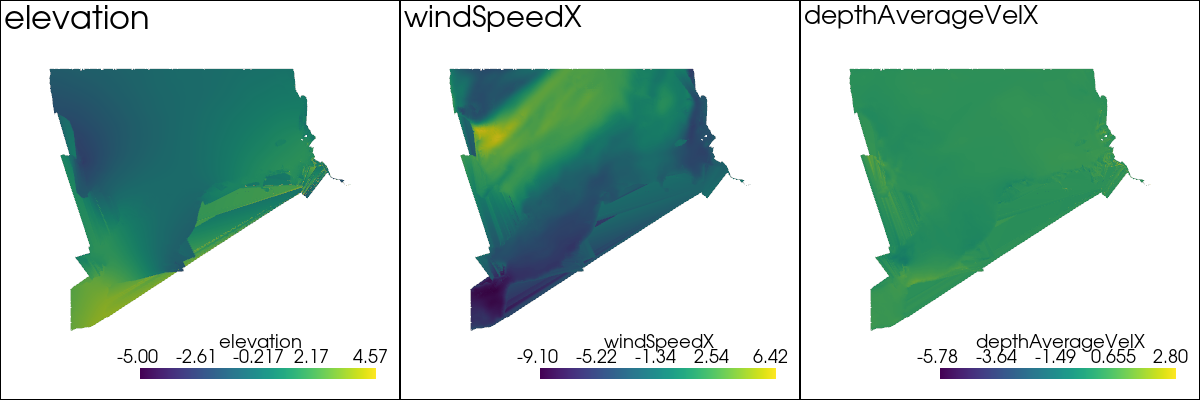

In [ ]:
plot_feature_map(tmin, ["elevation", "windSpeedX", "depthAverageVelX"])

/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


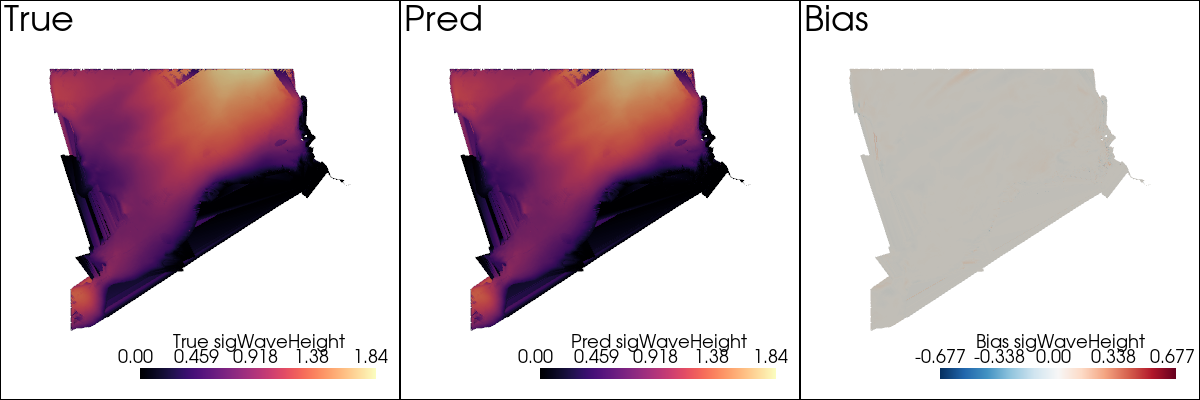

In [ ]:
plot_target_bias_map(tmin, "sigWaveHeight")

/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


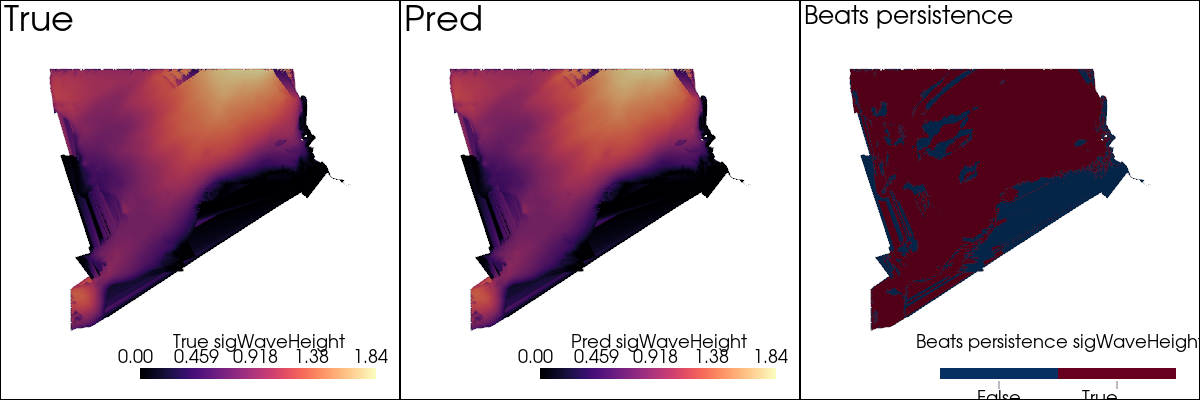

In [ ]:
plot_beat_persistence_map(tmin, "sigWaveHeight")

/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


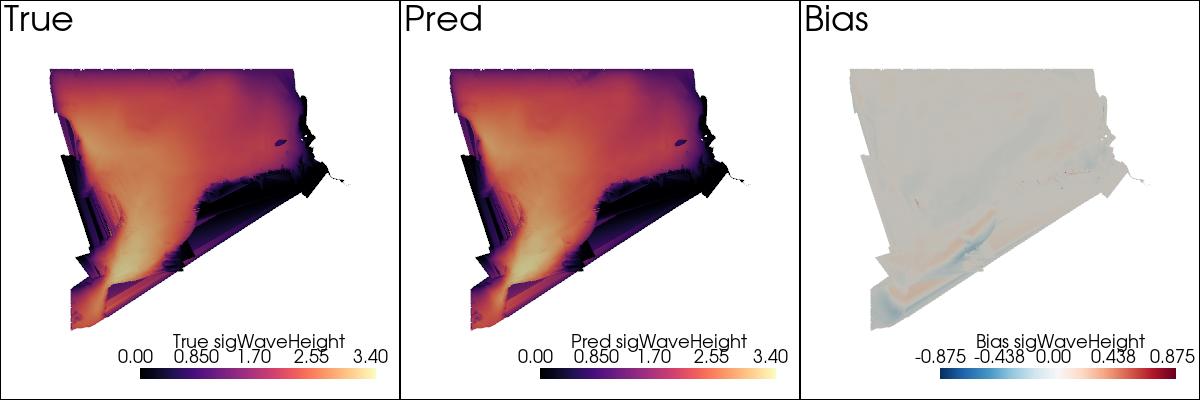

In [ ]:
plot_target_bias_map(tmax, "sigWaveHeight")

/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

cannot import name 'vtk' from 'trame.widgets' (/work/ka1176/caroline/gitlab/wave-wind-model-emulator/.venv/lib/python3.12/site-packages/trame/widgets/__init__.py)

Falling back to a static output.
  warnings.warn(


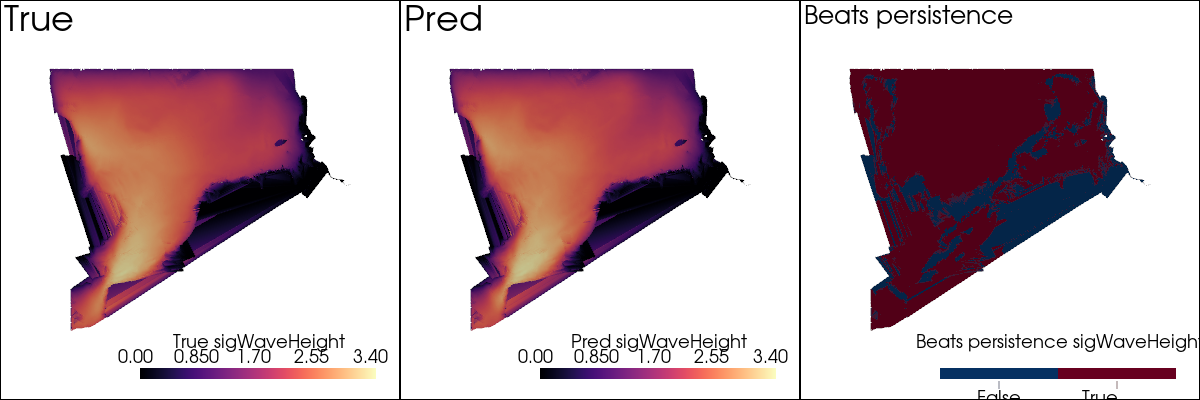

In [ ]:
plot_beat_persistence_map(tmax, "sigWaveHeight")

In [ ]:
node_ix = [210369, 212863, 214076]

/tmp/ipykernel_1687205/3424881046.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


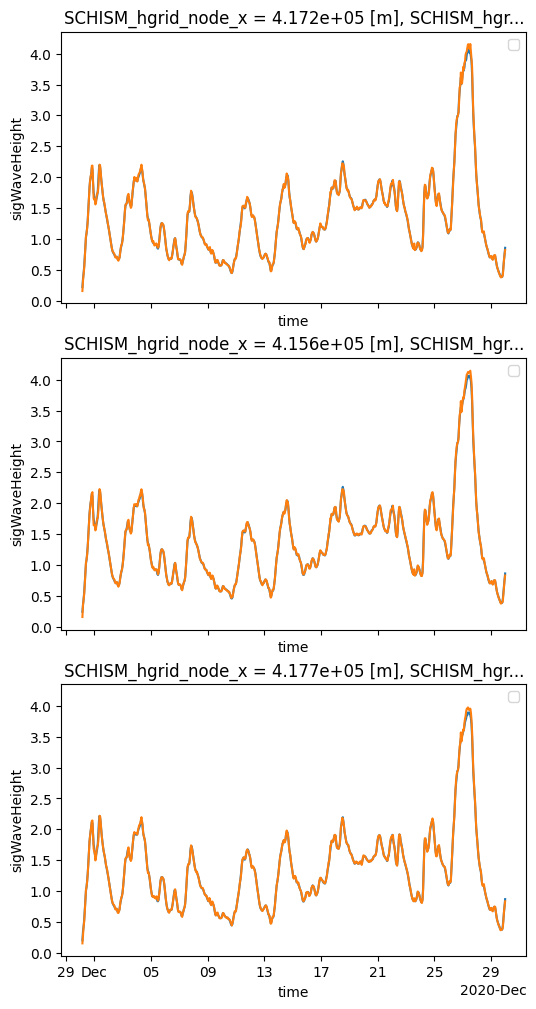

In [ ]:
fig, axs = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(6, 12))

for ix, ax in zip(node_ix, axs):
    ds_true.isel(nSCHISM_hgrid_node=ix)["sigWaveHeight"].plot(ax=ax)
    ds_pred.isel(nSCHISM_hgrid_node=ix)["sigWaveHeight"].plot(ax=ax)
    ax.legend()

## Persistence benchmark

In [ ]:
from sklearn.metrics import root_mean_squared_error

In [ ]:
#merged_ds = xr.merge([ds_true[["prev_sigWaveHeight", "sigWaveHeight", "windSpeedX", "windSpeedY"]], ds_pred.rename({"sigWaveHeight":"pred_sigWaveHeight", "delta_sigWaveHeight":"pred_delta_sigWaveHeight"})]).chunk("auto")

In [ ]:
merged_ds = xr.merge([ds_true[["prev_sigWaveHeight", "sigWaveHeight", "windSpeedX", "windSpeedY"]], ds_pred.rename({"sigWaveHeight":"pred_sigWaveHeight", })]).chunk("auto")

In [ ]:
merged_ds = merged_ds.isel(time=slice(1, None))

RMSE of this run

In [ ]:
root_mean_squared_error(merged_ds["sigWaveHeight"].values, merged_ds["pred_sigWaveHeight"].values)

0.02132497914135456

RMSE of the persistence benchmark

In [ ]:
root_mean_squared_error(merged_ds["sigWaveHeight"].values, merged_ds["prev_sigWaveHeight"].values)

0.06459487974643707

Model was better than the persistence benchmark in this percentage of samples

In [ ]:
(np.abs(merged_ds["sigWaveHeight"] - merged_ds["pred_sigWaveHeight"] ) < np.abs( merged_ds["sigWaveHeight"] - merged_ds["prev_sigWaveHeight"])).sum().compute() / len(merged_ds.time) / len(merged_ds.nSCHISM_hgrid_node)

<xarray.DataArray ()> Size: 8B
array(0.78169196)
Attributes:
    i23d:          1
    location:      node
    grid_mapping:  crs
    mesh:          SCHISM_hgrid

## Extremes

In [ ]:
merged_ds["bias_sigWaveHeight"] = merged_ds["pred_sigWaveHeight"] - merged_ds["sigWaveHeight"]

In [ ]:
merged_ds["bias_sigWaveHeight"].max().compute(), merged_ds["bias_sigWaveHeight"].min().compute()

(<xarray.DataArray 'bias_sigWaveHeight' ()> Size: 4B
 array(1.3184747, dtype=float32)
 Attributes:
     i23d:          1
     location:      node
     grid_mapping:  crs
     mesh:          SCHISM_hgrid,
 <xarray.DataArray 'bias_sigWaveHeight' ()> Size: 4B
 array(-1.8569441, dtype=float32)
 Attributes:
     i23d:          1
     location:      node
     grid_mapping:  crs
     mesh:          SCHISM_hgrid)

In [ ]:
merged_ds["true_delta_sigWaveHeight"] = merged_ds["sigWaveHeight"] - merged_ds["prev_sigWaveHeight"]

In [ ]:
deltas = merged_ds["true_delta_sigWaveHeight"].values.flatten()

In [ ]:
delta_plus = deltas[deltas>=0]
delta_minus = deltas[deltas<0]

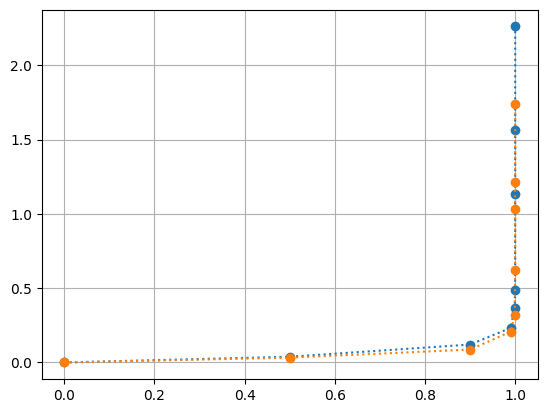

In [ ]:
quantiles = [0.0, 0.5, 0.9, 0.99, 0.999, 0.9999, 0.99999, 0.999999, 1.0]
plt.plot(quantiles, np.quantile(delta_plus, quantiles), 'o:')
plt.plot(quantiles, np.quantile(np.abs(delta_minus), quantiles), 'o:')
plt.grid()

In [ ]:
pq = np.quantile(delta_plus, quantiles)
mq = np.quantile(np.abs(delta_minus), quantiles)

In [ ]:
pq, mq

(array([0.        , 0.03860641, 0.12063462, 0.23252916, 0.36674595,
        0.48868505, 1.13446974, 1.56329187, 2.26191759]),
 array([1.03397577e-25, 3.24025154e-02, 8.69827271e-02, 2.06990242e-01,
        3.22025876e-01, 6.22216187e-01, 1.03563122e+00, 1.21508243e+00,
        1.74240077e+00]))

In [ ]:
all_q = np.array(list(mq[::-1]*-1) + list(pq[1:]))
all_q

array([-1.74240077e+00, -1.21508243e+00, -1.03563122e+00, -6.22216187e-01,
       -3.22025876e-01, -2.06990242e-01, -8.69827271e-02, -3.24025154e-02,
       -1.03397577e-25,  3.86064053e-02,  1.20634615e-01,  2.32529163e-01,
        3.66745949e-01,  4.88685047e-01,  1.13446974e+00,  1.56329187e+00,
        2.26191759e+00])

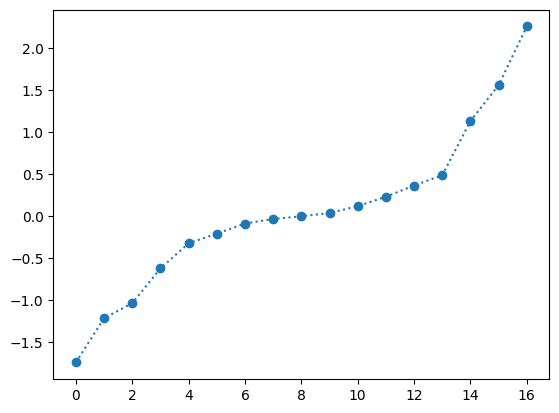

In [ ]:
plt.plot(all_q, 'o:')

In [ ]:
all_mean_bias = []
all_mean_rmse = []
all_bias = {}

for i in range(len(all_q)-1):
    print(i, all_q[i])
    selection = (merged_ds["true_delta_sigWaveHeight"] > all_q[i]) & (merged_ds["true_delta_sigWaveHeight"] <= all_q[i+1])
    selection = selection.compute()
    tmp = merged_ds["bias_sigWaveHeight"].where(selection, drop=True)
    all_mean_bias.append(np.mean(tmp).values)
    all_mean_rmse.append(np.mean(np.abs(tmp)).values)

    tmp = tmp.values.flatten()
    tmp = tmp[~np.isnan(tmp)]
    if len(tmp) > 10000:
        tmp = np.random.choice(tmp, size=10000, replace=False)
    all_bias[f"{all_q[i]:.2f} - {all_q[i+1]:.2f} m"] = tmp

0 -1.7424007654190063
1 -1.2150824334613048
2 -1.0356312170674897
3 -0.6222161870002765
4 -0.32202587628364654
5 -0.20699024200439453
6 -0.08698272705078125
7 -0.03240251541137695
8 -1.0339757656912846e-25
9 0.03860640525817871
10 0.12063461542129517
11 0.2325291633605957
12 0.3667459487915039
13 0.4886850465654504
14 1.1344697449266192
15 1.5632918678444305


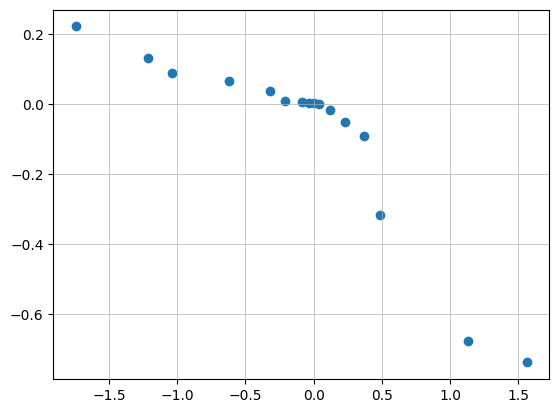

In [ ]:
plt.scatter(all_q[:len(all_mean_bias)], all_mean_bias)
plt.grid(":", lw=0.5)

/tmp/ipykernel_1687205/1383979145.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(all_bias.keys()), rotation=45)


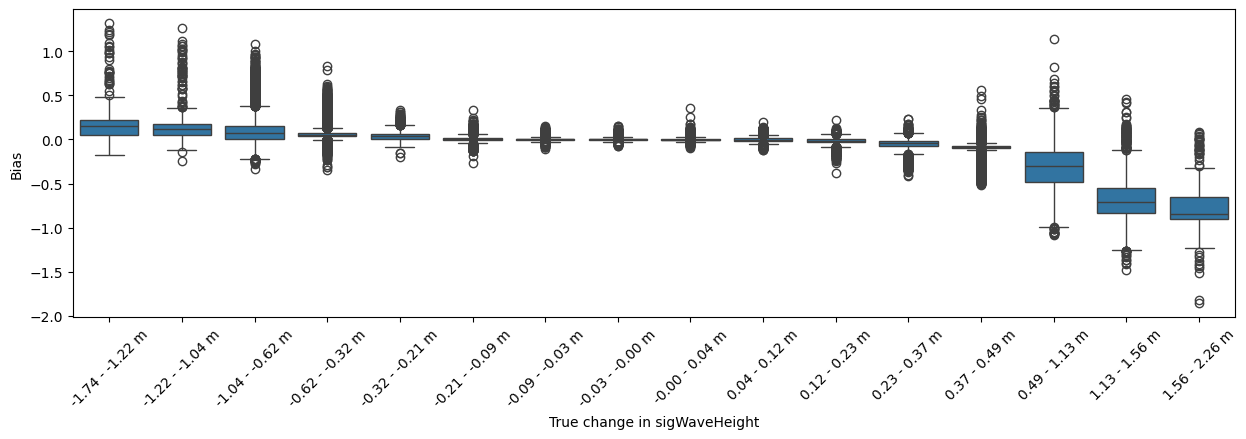

In [ ]:
pdf = pd.DataFrame([{r'True change in sigWaveHeight': key, 'Bias': value}
    for key, values in all_bias.items()
    for value in values])

fig, ax = plt.subplots(1, 1, figsize=(15, 4))
sns.set_style("whitegrid")

sns.boxplot(pdf, x=r'True change in sigWaveHeight', y="Bias")
ax.set_xticklabels(list(all_bias.keys()), rotation=45)
plt.savefig("tmp01.png", bbox_inches="tight")

In [ ]:
merged_ds["pred_delta_sigWaveHeight"].min().compute(), merged_ds["pred_delta_sigWaveHeight"].max().compute(), 

KeyError: "No variable named 'pred_delta_sigWaveHeight'. Did you mean one of ('true_delta_sigWaveHeight', 'pred_sigWaveHeight', 'prev_sigWaveHeight', 'bias_sigWaveHeight', 'sigWaveHeight')?"